Cargar el archivo Email_Spam.csv

In [1]:
import pandas as pd

file_path = 'Email_Spam.csv'
df = pd.read_csv(file_path)

print("Archivo cargado correctamente. Primeras 5 filas:")
print(df.head())
df.info()

print("\nValores nulos por columna:")
print(df.isnull().sum())

print("\nDistribución de la variable objetivo (spam):")
print(df['spam'].value_counts(normalize=True))

Archivo cargado correctamente. Primeras 5 filas:
   RecordID  word_freq_free  word_freq_money  word_freq_credit  word_freq_you  \
0  REC00001        2.425175         0.927166          2.350848          0.169   
1  REC00002        0.001000         0.063000          0.046000          0.222   
2  REC00003        0.499430         0.477281          2.305818          0.040   
3  REC00004             NaN         3.644461          1.331667          0.232   
4  REC00005        1.216935              NaN          0.700835          0.115   

   word_freq_email  word_freq_offer  word_freq_remove  word_freq_business  \
0            0.672            0.024             1.324               0.475   
1            0.054            0.092             0.621               0.400   
2            0.228            0.376             0.301               0.220   
3            0.466            0.204             0.059               0.430   
4            0.135            0.108             0.525               0.044   

 

Eliminar las variables RecordID, FullName, Phone, ZodiacSign, FavoriteColor, Hobby (irrelevantes) y capital_run_length_total (redundante con capital_run_length_average, r = 0,85)

In [2]:
cols_to_drop = ['RecordID', 'FullName', 'Phone', 'ZodiacSign',
                'FavoriteColor', 'Hobby', 'capital_run_length_total']

df = df.drop(columns=cols_to_drop)

print("Columnas eliminadas correctamente. Información actualizada del DataFrame:")
df.info()

Columnas eliminadas correctamente. Información actualizada del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_free              1838 non-null   float64
 1   word_freq_money             1834 non-null   float64
 2   word_freq_credit            2000 non-null   float64
 3   word_freq_you               2000 non-null   float64
 4   word_freq_email             2000 non-null   float64
 5   word_freq_offer             2000 non-null   float64
 6   word_freq_remove            2000 non-null   float64
 7   word_freq_business          2000 non-null   float64
 8   char_freq_excl              2000 non-null   float64
 9   char_freq_dollar            2000 non-null   float64
 10  capital_run_length_average  1843 non-null   float64
 11  capital_run_length_longest  2000 non-null   float64
 12  spam            

Aplicar One-Hot Encoding a la variable EmailDomain, eliminar la variable original y guardar la codificación (nombres de las columnas)

In [3]:
import joblib

df = pd.get_dummies(df, columns=['EmailDomain'], drop_first=True)

# Transformar True/False en 1/0
for col in df.columns:
    if df[col].dtype == 'bool':
        df[col] = df[col].astype(int)

# Guardar los nombres de las columnas de entrada (sin la variable objetivo)
features_schema = list(df.drop(columns=['spam']).columns)
joblib.dump(features_schema, 'one_hot_columns.joblib')

print("One-Hot Encoding aplicado a 'EmailDomain'.")
print(f"Total de columnas: {df.shape[1]}")
print("Codificación guardada en: 'one_hot_columns.joblib'")
print(df.head())

One-Hot Encoding aplicado a 'EmailDomain'.
Total de columnas: 71
Codificación guardada en: 'one_hot_columns.joblib'
   word_freq_free  word_freq_money  word_freq_credit  word_freq_you  \
0        2.425175         0.927166          2.350848          0.169   
1        0.001000         0.063000          0.046000          0.222   
2        0.499430         0.477281          2.305818          0.040   
3             NaN         3.644461          1.331667          0.232   
4        1.216935              NaN          0.700835          0.115   

   word_freq_email  word_freq_offer  word_freq_remove  word_freq_business  \
0            0.672            0.024             1.324               0.475   
1            0.054            0.092             0.621               0.400   
2            0.228            0.376             0.301               0.220   
3            0.466            0.204             0.059               0.430   
4            0.135            0.108             0.525               0.04

Imputar los valores nulos con la mediana, recortar los outliers de las variables de mayúsculas con el método IQR y normalizar las variables numéricas con MinMaxScaler. Guardar las medianas, los límites y el scaler.

In [4]:
from sklearn.preprocessing import MinMaxScaler
import joblib

# Variables numéricas (las dummies de EmailDomain ya están en 0/1)
num_cols = [c for c in df.columns if c.startswith(('word_freq', 'char_freq', 'capital_run'))]

# 1. Imputación con la mediana
medianas = df[num_cols].median()
df[num_cols] = df[num_cols].fillna(medianas)
joblib.dump(medianas, 'medianas_imputacion.joblib')

# 2. Outliers: capping con IQR solo en las variables de mayúsculas
outlier_cols = ['capital_run_length_average', 'capital_run_length_longest']
Q1 = df[outlier_cols].quantile(0.25)
Q3 = df[outlier_cols].quantile(0.75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR
print("Outliers recortados por variable:")
print(((df[outlier_cols] < lim_inf) | (df[outlier_cols] > lim_sup)).sum())
df[outlier_cols] = df[outlier_cols].clip(lower=lim_inf, upper=lim_sup, axis=1)
joblib.dump({'lim_inf': lim_inf, 'lim_sup': lim_sup}, 'limites_outliers.joblib')

# 3. Normalización MinMax
scaler = MinMaxScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
joblib.dump(scaler, 'min_max_scaler.joblib')
joblib.dump(num_cols, 'columnas_escaladas.joblib')

print("\nNulos restantes:", df.isnull().sum().sum())
print(df[num_cols].describe().T[['min', 'max']])
print("Medianas, límites y scaler guardados con joblib.")

Outliers recortados por variable:
capital_run_length_average    106
capital_run_length_longest    102
dtype: int64

Nulos restantes: 0
                            min  max
word_freq_free              0.0  1.0
word_freq_money             0.0  1.0
word_freq_credit            0.0  1.0
word_freq_you               0.0  1.0
word_freq_email             0.0  1.0
word_freq_offer             0.0  1.0
word_freq_remove            0.0  1.0
word_freq_business          0.0  1.0
char_freq_excl              0.0  1.0
char_freq_dollar            0.0  1.0
capital_run_length_average  0.0  1.0
capital_run_length_longest  0.0  1.0
Medianas, límites y scaler guardados con joblib.


Generar el modelo de regresión logística, mostrar los coeficientes calculados y las métricas de evaluación

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report)

# Variables de entrada (X) y variable objetivo (y)
X = df.drop(columns=['spam'])
y = df['spam']

# División 80/20 (stratify mantiene la proporción 65/35 en ambos conjuntos)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Entrenar el modelo
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

# Coeficientes
coef = pd.DataFrame({'Variable': X.columns,
                     'Coeficiente': log_reg.coef_[0]})
coef = coef.sort_values('Coeficiente', key=abs, ascending=False)
print(f"Intercepto: {log_reg.intercept_[0]:.4f}")
print("\nTop 15 coeficientes (por magnitud):")
print(coef.head(15).to_string(index=False))

# Métricas
y_pred = log_reg.predict(X_test)
y_proba = log_reg.predict_proba(X_test)[:, 1]

print("\n--- Métricas de evaluación ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")
print("\nMatriz de confusión:")
print(confusion_matrix(y_test, y_pred))
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=['No spam', 'Spam']))

Intercepto: -2.2726

Top 15 coeficientes (por magnitud):
                Variable  Coeficiente
        word_freq_credit     7.490423
          word_freq_free     7.330343
        char_freq_dollar     6.566772
         word_freq_money     6.211071
EmailDomain_domain48.com     0.976611
EmailDomain_domain14.com    -0.738289
EmailDomain_domain38.com    -0.725547
EmailDomain_domain22.com    -0.721979
EmailDomain_domain35.com    -0.604277
EmailDomain_domain21.com    -0.597837
 EmailDomain_domain4.com    -0.581674
EmailDomain_domain54.com    -0.566478
         word_freq_offer    -0.521752
EmailDomain_domain51.com    -0.515468
EmailDomain_domain11.com    -0.492036

--- Métricas de evaluación ---
Accuracy : 0.8650
Precision: 0.9778
Recall   : 0.6286
F1-score : 0.7652
ROC-AUC  : 0.9360

Matriz de confusión:
[[258   2]
 [ 52  88]]

Reporte de clasificación:
              precision    recall  f1-score   support

     No spam       0.83      0.99      0.91       260
        Spam       0.98      0.6

Entrenar 2 modelos de árbol de decisión, uno con división 70/30 para entrenamiento y prueba, y otro con cross validation. Graficar los árboles y generar las métricas

--- Árbol de decisión con división 70/30 ---
Profundidad del árbol: 19
Accuracy : 0.8083
Precision: 0.7251
Recall   : 0.7286
F1-score : 0.7268
ROC-AUC  : 0.7899
Matriz de confusión:
[[332  58]
 [ 57 153]]


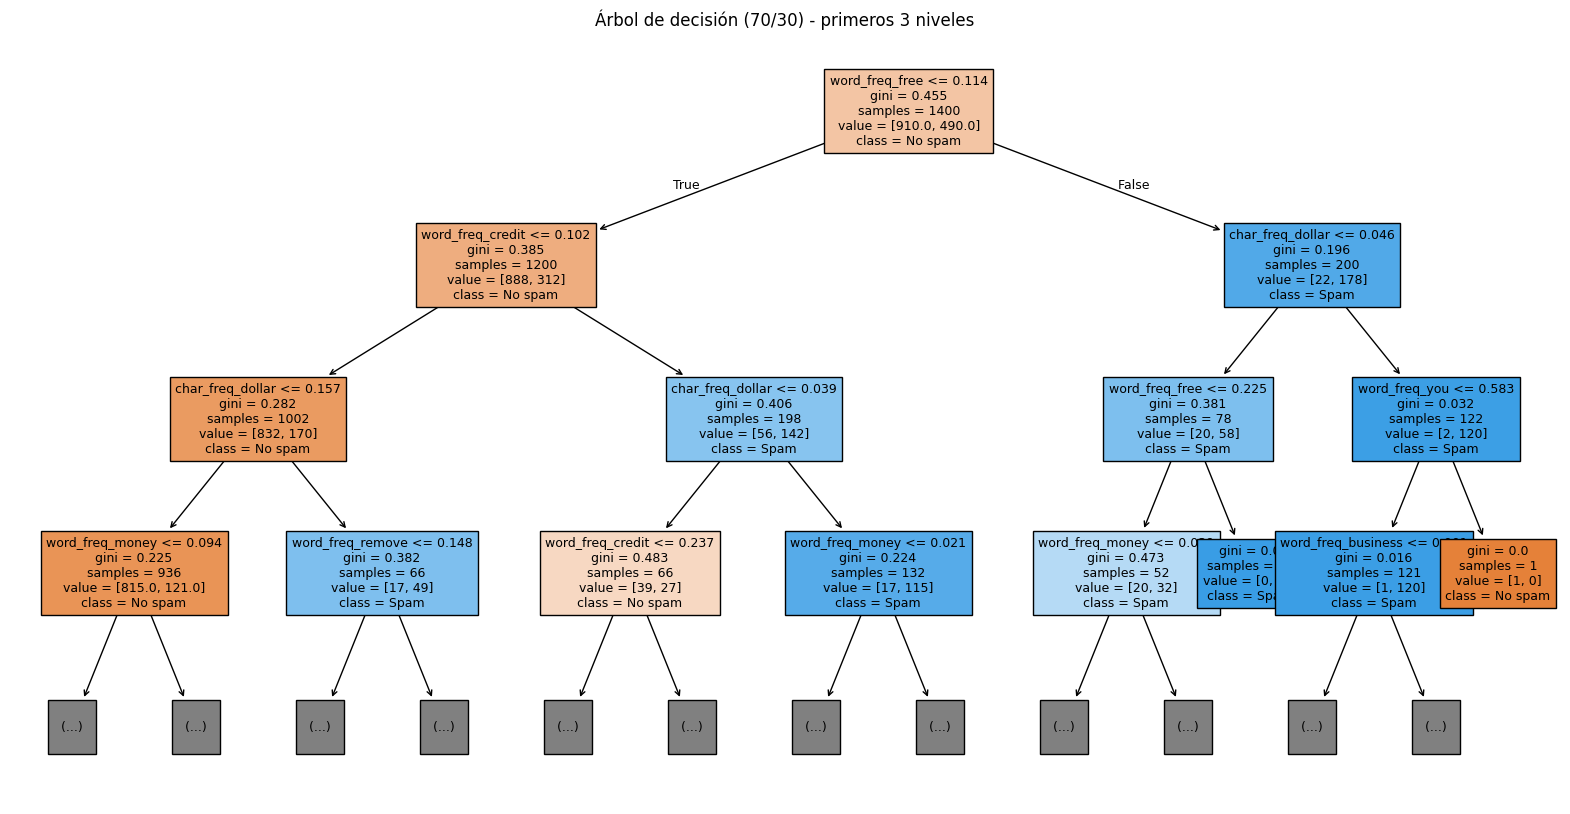


--- Árbol de decisión con Cross Validation (5 folds) ---
accuracy  : 0.8085 (+/- 0.0211)
precision : 0.7231 (+/- 0.0422)
recall    : 0.7386 (+/- 0.0073)
f1        : 0.7303 (+/- 0.0239)
roc_auc   : 0.7924 (+/- 0.0176)


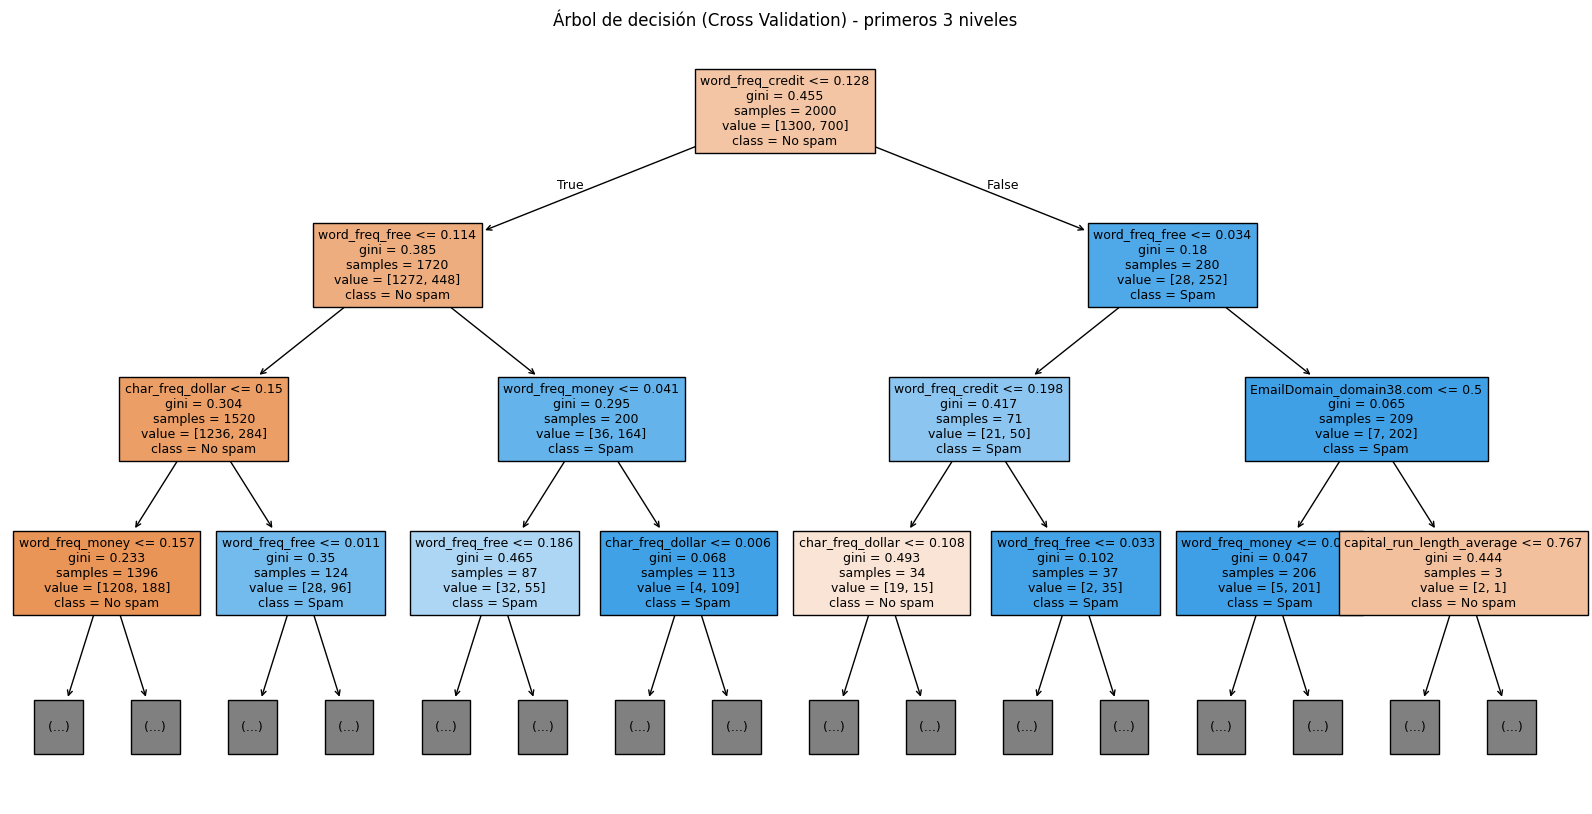

In [6]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)
import matplotlib.pyplot as plt

# ---------- Modelo 1: división 70/30 ----------
print("--- Árbol de decisión con división 70/30 ---")
X_train_70, X_test_30, y_train_70, y_test_30 = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

dtree_70_30 = DecisionTreeClassifier(random_state=42)
dtree_70_30.fit(X_train_70, y_train_70)

y_pred_dt = dtree_70_30.predict(X_test_30)
y_proba_dt = dtree_70_30.predict_proba(X_test_30)[:, 1]

print(f"Profundidad del árbol: {dtree_70_30.get_depth()}")
print(f"Accuracy : {accuracy_score(y_test_30, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test_30, y_pred_dt):.4f}")
print(f"Recall   : {recall_score(y_test_30, y_pred_dt):.4f}")
print(f"F1-score : {f1_score(y_test_30, y_pred_dt):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test_30, y_proba_dt):.4f}")
print("Matriz de confusión:")
print(confusion_matrix(y_test_30, y_pred_dt))

plt.figure(figsize=(20, 10))
plot_tree(dtree_70_30, feature_names=X.columns, class_names=['No spam', 'Spam'],
          filled=True, max_depth=3, fontsize=9)
plt.title("Árbol de decisión (70/30) - primeros 3 niveles")
plt.show()

# ---------- Modelo 2: cross validation (5 folds) ----------
print("\n--- Árbol de decisión con Cross Validation (5 folds) ---")
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

dtree_cv = DecisionTreeClassifier(random_state=42)
resultados_cv = cross_validate(dtree_cv, X, y, cv=kf, scoring=metricas)

for m in metricas:
    scores = resultados_cv[f'test_{m}']
    print(f"{m:<10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Entrenar con todos los datos para graficar
dtree_cv.fit(X, y)
plt.figure(figsize=(20, 10))
plot_tree(dtree_cv, feature_names=X.columns, class_names=['No spam', 'Spam'],
          filled=True, max_depth=3, fontsize=9)
plt.title("Árbol de decisión (Cross Validation) - primeros 3 niveles")
plt.show()

Entrenar un modelo Random Forest con cross validation y calcular las métricas de evaluación

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

print("--- Random Forest con Cross Validation (5 folds) ---")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

rf_cv = RandomForestClassifier(n_estimators=100, random_state=42)
resultados_rf = cross_validate(rf_cv, X, y, cv=kf, scoring=metricas)

for m in metricas:
    scores = resultados_rf[f'test_{m}']
    print(f"{m:<10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

# Importancia de las variables (entrenando con todos los datos)
rf_cv.fit(X, y)
importancias = pd.Series(rf_cv.feature_importances_, index=X.columns)
print("\nTop 10 variables más importantes:")
print(importancias.sort_values(ascending=False).head(10))

--- Random Forest con Cross Validation (5 folds) ---
accuracy  : 0.8830 (+/- 0.0093)
precision : 0.8840 (+/- 0.0227)
recall    : 0.7671 (+/- 0.0258)
f1        : 0.8210 (+/- 0.0151)
roc_auc   : 0.9159 (+/- 0.0101)

Top 10 variables más importantes:
word_freq_credit      0.188873
word_freq_free        0.161557
char_freq_dollar      0.158846
word_freq_money       0.140479
word_freq_remove      0.035954
char_freq_excl        0.035016
word_freq_you         0.033645
word_freq_email       0.033575
word_freq_business    0.033530
word_freq_offer       0.033009
dtype: float64


Entrenar modelos KNN con cross validation para diferentes valores de K y calcular las métricas. Comparar con y sin las variables dummies de EmailDomain

In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

print("--- K-Nearest Neighbors (KNN) con Cross Validation (5 folds) ---")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
k_values = [3, 5, 7, 9, 11, 15, 21]

# Variables sin las dummies de EmailDomain
X_sin_dominio = X[[c for c in X.columns if not c.startswith('EmailDomain_')]]

for nombre, X_knn in [('Con EmailDomain', X), ('Sin EmailDomain', X_sin_dominio)]:
    resultados_knn = []
    for k in k_values:
        knn = KNeighborsClassifier(n_neighbors=k)
        res = cross_validate(knn, X_knn, y, cv=kf, scoring=metricas)
        fila = {'K': k}
        for m in metricas:
            fila[m] = res[f'test_{m}'].mean()
        resultados_knn.append(fila)

    tabla_knn = pd.DataFrame(resultados_knn)
    print(f"\n=== KNN {nombre} ({X_knn.shape[1]} variables) ===")
    print(tabla_knn.round(4).to_string(index=False))
    mejor = tabla_knn.loc[tabla_knn['f1'].idxmax()]
    print(f"Mejor K según F1: {int(mejor['K'])} (F1 = {mejor['f1']:.4f})")

--- K-Nearest Neighbors (KNN) con Cross Validation (5 folds) ---

=== KNN Con EmailDomain (70 variables) ===
 K  accuracy  precision  recall     f1  roc_auc
 3    0.6575     0.5223  0.2614 0.3480   0.6061
 5    0.6550     0.5168  0.1943 0.2821   0.6015
 7    0.6610     0.5433  0.1800 0.2696   0.6141
 9    0.6540     0.5233  0.1386 0.2183   0.6070
11    0.6480     0.4851  0.1100 0.1777   0.5966
15    0.6480     0.4709  0.0971 0.1596   0.5801
21    0.6405     0.4145  0.0686 0.1172   0.5575
Mejor K según F1: 3 (F1 = 0.3480)

=== KNN Sin EmailDomain (12 variables) ===
 K  accuracy  precision  recall     f1  roc_auc
 3    0.7840     0.8254  0.4871 0.6122   0.7720
 5    0.7905     0.8917  0.4571 0.6043   0.7902
 7    0.7895     0.9301  0.4314 0.5890   0.8075
 9    0.7880     0.9631  0.4100 0.5749   0.8132
11    0.7885     0.9893  0.4000 0.5696   0.8105
15    0.7780     0.9962  0.3671 0.5364   0.8139
21    0.7695     1.0000  0.3414 0.5085   0.8195
Mejor K según F1: 3 (F1 = 0.6122)


Entrenar un modelo de máquina de soporte vectorial (SVM) con cross validation y generar las métricas de evaluación

In [9]:
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate

print("--- Support Vector Machine (SVC) con Cross Validation (5 folds) ---")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

for kernel in ['rbf', 'linear']:
    svm_cv = SVC(kernel=kernel, random_state=42)
    resultados_svm = cross_validate(svm_cv, X, y, cv=kf, scoring=metricas)

    print(f"\n=== SVM con kernel '{kernel}' ===")
    for m in metricas:
        scores = resultados_svm[f'test_{m}']
        print(f"{m:<10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

--- Support Vector Machine (SVC) con Cross Validation (5 folds) ---

=== SVM con kernel 'rbf' ===
accuracy  : 0.8385 (+/- 0.0106)
precision : 0.9594 (+/- 0.0236)
recall    : 0.5629 (+/- 0.0298)
f1        : 0.7089 (+/- 0.0238)
roc_auc   : 0.9061 (+/- 0.0094)

=== SVM con kernel 'linear' ===
accuracy  : 0.8670 (+/- 0.0133)
precision : 0.9503 (+/- 0.0275)
recall    : 0.6543 (+/- 0.0215)
f1        : 0.7749 (+/- 0.0229)
roc_auc   : 0.9212 (+/- 0.0081)


Entrenar un modelo de red neuronal con cross validation y generar las métricas de evaluación

In [10]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
import warnings
warnings.filterwarnings('ignore')

print("--- Red Neuronal (MLPClassifier) con Cross Validation (5 folds) ---")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# 2 capas ocultas (64 y 32 neuronas), activación ReLU
# early_stopping detiene el entrenamiento si deja de mejorar (evita sobreajuste)
mlp_cv = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu',
                       max_iter=1000, early_stopping=True, random_state=42)

resultados_mlp = cross_validate(mlp_cv, X, y, cv=kf, scoring=metricas)

for m in metricas:
    scores = resultados_mlp[f'test_{m}']
    print(f"{m:<10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

--- Red Neuronal (MLPClassifier) con Cross Validation (5 folds) ---
accuracy  : 0.8635 (+/- 0.0120)
precision : 0.8714 (+/- 0.0339)
recall    : 0.7171 (+/- 0.0205)
f1        : 0.7863 (+/- 0.0172)
roc_auc   : 0.9098 (+/- 0.0111)


Entrenar un modelo Bagging con cross validation y generar las métricas de evaluación

In [11]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

print("--- Bagging Classifier con Cross Validation (5 folds) ---")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# 100 árboles de decisión, cada uno entrenado con una muestra bootstrap distinta
bagging_cv = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                               n_estimators=100, random_state=42)

resultados_bag = cross_validate(bagging_cv, X, y, cv=kf, scoring=metricas)

for m in metricas:
    scores = resultados_bag[f'test_{m}']
    print(f"{m:<10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

--- Bagging Classifier con Cross Validation (5 folds) ---
accuracy  : 0.8785 (+/- 0.0102)
precision : 0.8568 (+/- 0.0186)
recall    : 0.7843 (+/- 0.0219)
f1        : 0.8187 (+/- 0.0159)
roc_auc   : 0.9120 (+/- 0.0099)


Entrenar un modelo Boosting con cross validation y generar las métricas de evaluación

In [12]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

print("--- Gradient Boosting Classifier con Cross Validation (5 folds) ---")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Árboles secuenciales: cada uno corrige los errores del anterior
boosting_cv = GradientBoostingClassifier(random_state=42)

resultados_gb = cross_validate(boosting_cv, X, y, cv=kf, scoring=metricas)

for m in metricas:
    scores = resultados_gb[f'test_{m}']
    print(f"{m:<10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

--- Gradient Boosting Classifier con Cross Validation (5 folds) ---
accuracy  : 0.8760 (+/- 0.0163)
precision : 0.8607 (+/- 0.0331)
recall    : 0.7714 (+/- 0.0293)
f1        : 0.8132 (+/- 0.0247)
roc_auc   : 0.9223 (+/- 0.0084)


Entrenar un modelo Stacking con cross validation y generar las métricas de evaluación

In [13]:
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

print("--- Stacking Classifier con Cross Validation (5 folds) ---")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Modelos base (nivel 0)
modelos_base = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('gb', GradientBoostingClassifier(random_state=42)),
    ('svm', SVC(kernel='linear', random_state=42))
]

# Meta-modelo (nivel 1): combina las predicciones de los modelos base
stacking_cv = StackingClassifier(estimators=modelos_base,
                                 final_estimator=LogisticRegression(max_iter=1000),
                                 cv=5)

resultados_stack = cross_validate(stacking_cv, X, y, cv=kf, scoring=metricas, n_jobs=-1)

for m in metricas:
    scores = resultados_stack[f'test_{m}']
    print(f"{m:<10}: {scores.mean():.4f} (+/- {scores.std():.4f})")

--- Stacking Classifier con Cross Validation (5 folds) ---
accuracy  : 0.8810 (+/- 0.0131)
precision : 0.8727 (+/- 0.0329)
recall    : 0.7743 (+/- 0.0190)
f1        : 0.8201 (+/- 0.0176)
roc_auc   : 0.9263 (+/- 0.0062)


Optimizar los hiperparámetros de todos los modelos con GridSearchCV (métrica F1), incluyendo el balanceo de clases con class_weight, y comparar el F1 antes y después de optimizar

In [14]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, BaggingClassifier,
                              GradientBoostingClassifier, StackingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# 1. Espacios de búsqueda de hiperparámetros
param_grids = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'params': {'C': [0.1, 1, 10, 100], 'class_weight': [None, 'balanced']}
    },
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {'max_depth': [3, 5, 10, None], 'min_samples_split': [2, 5, 10],
                   'class_weight': [None, 'balanced']}
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {'n_estimators': [50, 100], 'max_depth': [5, 10, None],
                   'min_samples_split': [2, 5], 'class_weight': [None, 'balanced']}
    },
    'SVM': {
        'model': SVC(random_state=42),
        'params': {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear'],
                   'class_weight': [None, 'balanced']}
    },
    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {'n_neighbors': [3, 5, 7, 9, 11], 'weights': ['uniform', 'distance']}
    },
    'Neural Network': {
        'model': MLPClassifier(max_iter=1000, early_stopping=True, random_state=42),
        'params': {'hidden_layer_sizes': [(50,), (100,), (64, 32)], 'alpha': [0.0001, 0.001, 0.01]}
    },
    'Bagging': {
        'model': BaggingClassifier(random_state=42),
        'params': {'n_estimators': [10, 50, 100], 'max_samples': [0.5, 0.8, 1.0]}
    },
    'Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'params': {'n_estimators': [50, 100], 'learning_rate': [0.01, 0.1, 0.2], 'max_depth': [3, 5]}
    }
}

# 2. F1 antes de optimizar (valores obtenidos en las celdas anteriores)
f1_antes = {
    'Logistic Regression': 0.7652,  # división 80/20
    'Decision Tree': 0.7303,
    'Random Forest': 0.8210,
    'SVM': 0.7749,                  # kernel linear
    'KNN': 0.3480,                  # K=3, con EmailDomain
    'Neural Network': 0.7863,
    'Bagging': 0.8187,
    'Boosting': 0.8132,
    'Stacking': 0.8208
}

# 3. Optimizar cada modelo con GridSearchCV y evaluarlo con CV
resultados = {}
best_models = {}

for name, config in param_grids.items():
    print(f"Optimizando {name} con GridSearchCV...")
    grid_search = GridSearchCV(config['model'], config['params'],
                               cv=kf, scoring='f1', n_jobs=-1)
    grid_search.fit(X, y)
    best_models[name] = grid_search.best_estimator_

    res = cross_validate(grid_search.best_estimator_, X, y, cv=kf,
                         scoring=metricas, n_jobs=-1)
    resultados[name] = {m: res[f'test_{m}'].mean() for m in metricas}
    print(f"  -> Mejores parámetros: {grid_search.best_params_}")
    print(f"  -> Nuevo F1: {resultados[name]['f1']:.4f}")

# 4. Stacking con los modelos base ya optimizados
print("Optimizando Stacking con los estimadores optimizados...")
stacking_opt = StackingClassifier(
    estimators=[('rf', best_models['Random Forest']),
                ('gb', best_models['Boosting']),
                ('svm', best_models['SVM'])],
    final_estimator=LogisticRegression(max_iter=1000), cv=5)
res = cross_validate(stacking_opt, X, y, cv=kf, scoring=metricas, n_jobs=-1)
resultados['Stacking'] = {m: res[f'test_{m}'].mean() for m in metricas}
best_models['Stacking'] = stacking_opt
print(f"  -> Nuevo F1 para Stacking: {resultados['Stacking']['f1']:.4f}")

# 5. Comparación final
comparacion = pd.DataFrame(resultados).T
comparacion.insert(0, 'F1 antes', pd.Series(f1_antes))
comparacion['Mejora F1'] = comparacion['f1'] - comparacion['F1 antes']
comparacion = comparacion.sort_values('f1', ascending=False)

print("\n=== COMPARACIÓN DE MODELOS OPTIMIZADOS ===")
print(comparacion.round(4))

Optimizando Logistic Regression con GridSearchCV...
  -> Mejores parámetros: {'C': 10, 'class_weight': 'balanced'}
  -> Nuevo F1: 0.8115
Optimizando Decision Tree con GridSearchCV...
  -> Mejores parámetros: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_split': 10}
  -> Nuevo F1: 0.7877
Optimizando Random Forest con GridSearchCV...
  -> Mejores parámetros: {'class_weight': None, 'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
  -> Nuevo F1: 0.8244
Optimizando SVM con GridSearchCV...
  -> Mejores parámetros: {'C': 10, 'class_weight': None, 'kernel': 'linear'}
  -> Nuevo F1: 0.8082
Optimizando KNN con GridSearchCV...
  -> Mejores parámetros: {'n_neighbors': 3, 'weights': 'distance'}
  -> Nuevo F1: 0.3496
Optimizando Neural Network con GridSearchCV...
  -> Mejores parámetros: {'alpha': 0.0001, 'hidden_layer_sizes': (64, 32)}
  -> Nuevo F1: 0.7863
Optimizando Bagging con GridSearchCV...
  -> Mejores parámetros: {'max_samples': 1.0, 'n_estimators': 100}
  -> Nuev

Guardar el One-Hot Encoding, el MinMaxScaler, las medianas, los límites de outliers y el modelo Random Forest optimizado con joblib

In [15]:
import joblib

# El One-Hot Encoding, el scaler, las medianas y los límites ya se guardaron en los pasos 2 y 3
print("Ya guardados: one_hot_columns.joblib, min_max_scaler.joblib,")
print("              medianas_imputacion.joblib, limites_outliers.joblib, columnas_escaladas.joblib")

# Entrenar el mejor modelo con todos los datos y guardarlo
modelo_final = best_models['Random Forest']
modelo_final.fit(X, y)
joblib.dump(modelo_final, 'random_forest_optimizado.joblib')
print("Modelo Random Forest optimizado guardado en: 'random_forest_optimizado.joblib'")

Ya guardados: one_hot_columns.joblib, min_max_scaler.joblib,
              medianas_imputacion.joblib, limites_outliers.joblib, columnas_escaladas.joblib
Modelo Random Forest optimizado guardado en: 'random_forest_optimizado.joblib'


Realizar una predicción con el modelo Random Forest optimizado usando los datos del archivo DatosPrueba.csv, aplicando la pipeline completa

In [18]:
import pandas as pd
import numpy as np
import joblib

# Cargar todo lo guardado
modelo = joblib.load('random_forest_optimizado.joblib')
scaler = joblib.load('min_max_scaler.joblib')
columnas_modelo = joblib.load('one_hot_columns.joblib')
columnas_escaladas = joblib.load('columnas_escaladas.joblib')
medianas = joblib.load('medianas_imputacion.joblib')
limites = joblib.load('limites_outliers.joblib')

# Cargar los datos nuevos
test_df = pd.read_csv('DatosPrueba.csv')
print("Datos de prueba cargados:")
print(test_df.head(6))
ids = test_df['RecordID']

# Paso 0: eliminar la variable objetivo (si viene)
test_df = test_df.drop(columns=['spam'], errors='ignore')

# Paso 1: eliminar las variables irrelevantes y la redundante
test_df = test_df.drop(columns=['RecordID', 'FullName', 'Phone', 'ZodiacSign',
                                'FavoriteColor', 'Hobby', 'capital_run_length_total'],
                       errors='ignore')

# Paso 2: One-Hot Encoding con las mismas columnas del entrenamiento
test_df = pd.get_dummies(test_df, columns=['EmailDomain'])
test_df = test_df.reindex(columns=columnas_modelo, fill_value=0)
for col in test_df.columns:
    if test_df[col].dtype == 'bool':
        test_df[col] = test_df[col].astype(int)

# Paso 3: imputar, recortar outliers y escalar con lo guardado
test_df[columnas_escaladas] = test_df[columnas_escaladas].fillna(medianas)
outlier_cols = list(limites['lim_inf'].index)
test_df[outlier_cols] = test_df[outlier_cols].clip(lower=limites['lim_inf'],
                                                   upper=limites['lim_sup'], axis=1)
test_df[columnas_escaladas] = scaler.transform(test_df[columnas_escaladas])

# Paso 4: predecir con el modelo guardado
pred = modelo.predict(test_df)
prob = modelo.predict_proba(test_df)[:, 1]

resultado = pd.DataFrame({'RecordID': ids,
                          'Prob_spam': prob.round(3),
                          'Predicción': np.where(pred == 1, 'SPAM', 'No spam')})
print("\n=== PREDICCIONES ===")
print(resultado.to_string(index=False))

Datos de prueba cargados:
  RecordID  word_freq_free  word_freq_money  word_freq_credit  word_freq_you  \
0     T001             2.5              1.8               2.1            0.6   
1     T002             0.0              0.1               0.0            0.4   
2     T003             NaN              2.4               1.5            0.3   
3     T004             0.1              0.0               0.1            0.7   
4     T005             1.2              0.2               0.0            0.5   
5     T006             0.4              0.3               0.2            0.2   

   word_freq_email  word_freq_offer  word_freq_remove  word_freq_business  \
0              0.2              0.9               0.5                 0.3   
1              0.5              0.1               0.0                 0.3   
2              0.1              0.4               0.6                 0.2   
3              0.6              0.0               0.1                 0.5   
4              0.3          